# Smart IDS v3 — Notebook 06: Explainable AI & Feature Attribution via SHAP
TreeExplainer, KernelExplainer, and Single-Sample Waterfall Decomposition

---

### What You Will Learn
1. **The Need for Explainability in SOCs**: Why black-box predictions are an operational liability in incident response.
2. **Game Theory Foundations**: How Shapley values fairly distribute credit among features.
3. **SHAP TreeExplainer**: Fast, exact global feature importance and attack beeswarm plots for XGBoost.
4. **SHAP KernelExplainer**: Model-agnostic attribution for the deep MLP with defensive multi-class shape handling.
5. **Waterfall Decomposition**: Dissecting a single critical detection event into its exact additive feature contributions.

---

### Prerequisites
- Completion of Notebooks 01 through 05.
- Understanding of feature importance concepts.


## 1. Security Concept: The Black-Box Problem in Security Operations

> **Security Concept: Why Black-Box AI Fails in a SOC**
> If an automated IDS triggers a high-severity alert and instructs a firewall to block an IP address, human security analysts must immediately answer:
> 1. *Why* did the model flag this flow?
> 2. Is this an actual zero-day attack, or did a regular user just download a large video file?
> 
> Without explainability, analysts experience **alert fatigue** or disregard the AI's recommendations. SHAP (SHapley Additive exPlanations) provides mathematically guaranteed, human-auditable explanations for every single decision.


In [1]:
import sys
from pathlib import Path

cur = Path.cwd()
root = cur if (cur / 'src').exists() else cur.parent
if str(root / 'src') not in sys.path:
    sys.path.insert(0, str(root / 'src'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import tensorflow as tf

from smart_ids.config import (
    CLASS_NAMES,
    MODELS_DIR,
    PROCESSED_DATA_DIR,
    SEED,
)
from smart_ids.artifacts import (
    load_xgboost_model,
    load_feature_names,
)
from smart_ids.explain import (
    compute_shap_xgboost,
    compute_shap_mlp,
    generate_waterfall_plot,
)

np.random.seed(SEED)
print(f"SHAP version: {shap.__version__}")


SHAP version: 0.45.1


## 2. Loading Models, Test Data, and Feature Schema

We load the trained XGBoost model, the Keras MLP, and the standardized test features.


In [2]:
xgb_model = load_xgboost_model(MODELS_DIR / 'xgb_model.json')
mlp_model = tf.keras.models.load_model(MODELS_DIR / 'best_mlp.keras')
feature_names = load_feature_names(MODELS_DIR / 'feature_names.json')

X_test_scaled = np.load(PROCESSED_DATA_DIR / 'X_test_scaled.npy')
y_test = np.load(PROCESSED_DATA_DIR / 'y_test.npy')

print(f"Loaded {len(feature_names)} feature names.")
print(f"Test samples available: {len(X_test_scaled):,}")


Loaded 77 feature names.
Test samples available: 3,750


## 3. TreeExplainer for XGBoost: Global Feature Importance

**What we do and why:**
`TreeExplainer` exploits tree structure to compute exact Shapley values in polynomial time. We evaluate 500 test samples and plot:
1. Global feature importance bar chart (ranking features across all attack classes).
2. Beeswarm summary plot for DoS Hulk (showing whether high or low values trigger the detection).


In [3]:
explainer_xgb, shap_values_xgb, X_shap_df = compute_shap_xgboost(
    xgb_model,
    X_test_scaled,
    feature_names,
    n_samples=500,
)

# 1. Global Feature Importance Bar Chart
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_xgb, X_shap_df, plot_type='bar', show=False, max_display=15)
plt.title("XGBoost — Global Feature Importance (Top 15 Features)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


<Figure size 1000x600 with 0 Axes>

<Figure size 2350x1300 with 8 Axes>

## 4. Beeswarm Summary Plot for DoS Hulk (Class Index 1)

**What we do and why:**
In the beeswarm plot:
- Each dot is a flow.
- Red color indicates a high feature value, blue indicates a low value.
- Horizontal position indicates whether that feature increases (right) or decreases (left) the probability of DoS Hulk.


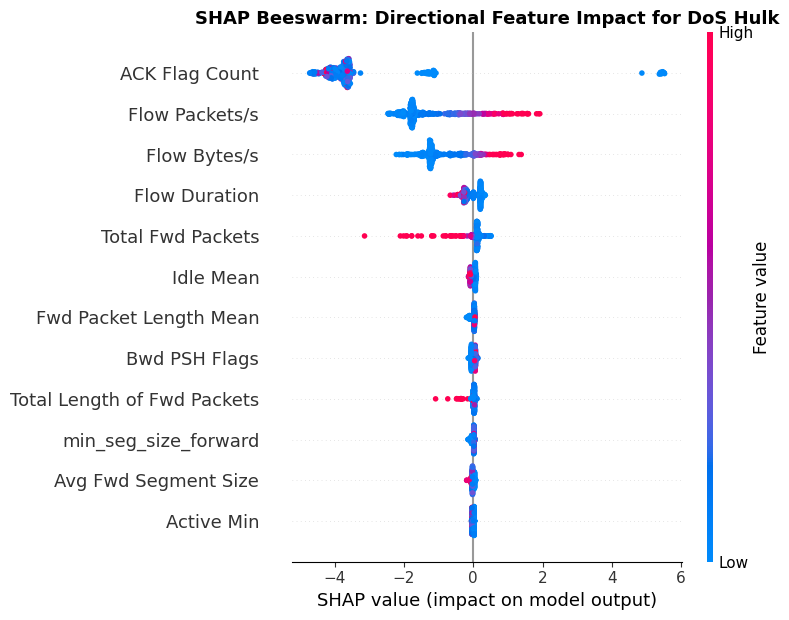

In [4]:
# Extract SHAP values for class 1 (DoS Hulk)
if isinstance(shap_values_xgb, list):
    shap_vals_class1 = shap_values_xgb[1]
elif isinstance(shap_values_xgb, np.ndarray) and len(shap_values_xgb.shape) == 3:
    shap_vals_class1 = shap_values_xgb[:, :, 1]
else:
    shap_vals_class1 = shap_values_xgb

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_class1, X_shap_df, show=False, max_display=12)
plt.title("SHAP Beeswarm: Directional Feature Impact for DoS Hulk", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 5. KernelExplainer for Deep MLP (Model-Agnostic Attribution)

**What we do and why:**
Unlike trees, neural networks do not have an exact tree algorithm. We use `KernelExplainer`, which perturbs features and measures the change in model output.
To keep the computation fast and responsive, we use a 10-sample reference background and explain 20 test flows.


  0%|          | 0/20 [00:00<?, ?it/s]

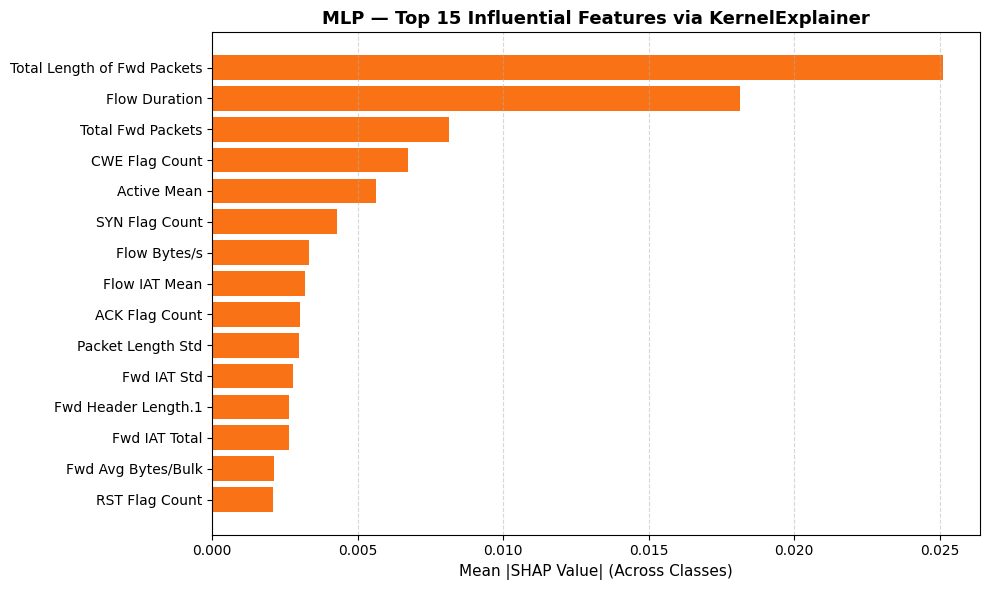

In [5]:
explainer_mlp, mean_abs_shap_mlp, _ = compute_shap_mlp(
    mlp_model,
    X_test_scaled,
    feature_names,
    n_background=10,
    n_samples=20,
)

# Plot top 15 features for MLP
top_indices = np.argsort(mean_abs_shap_mlp)[-15:]
plt.figure(figsize=(10, 6))
plt.barh(range(len(top_indices)), mean_abs_shap_mlp[top_indices], color='#f97316')
plt.yticks(range(len(top_indices)), [feature_names[i] for i in top_indices])
plt.xlabel("Mean |SHAP Value| (Across Classes)", fontsize=11)
plt.title("MLP — Top 15 Influential Features via KernelExplainer", fontsize=13, fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## 6. Single-Sample Waterfall Decomposition: Explaining a Critical Attack Flow

**What we do and why:**
When a critical intrusion occurs, security analysts need a forensic report explaining that specific flow.
We programmatically locate a true positive attack sample and generate a **Waterfall Plot** showing how each feature shifted the prediction from the base value to the final attack confidence.


Explaining flow #36: True Class='DoS Hulk', Predicted='DoS Hulk'


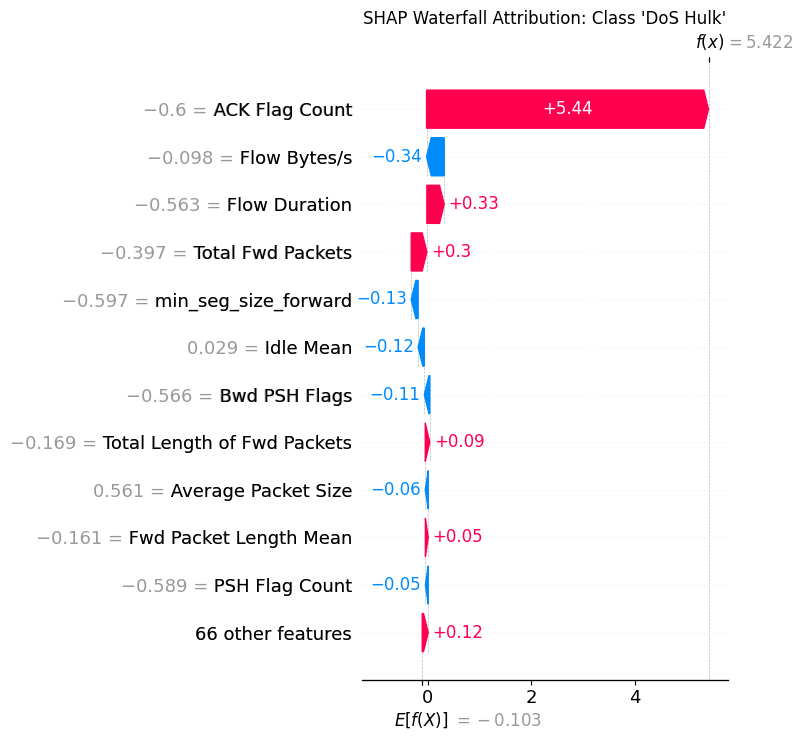

In [6]:
# Find a genuine True Positive attack sample (e.g., DoS Hulk, class 1)
y_pred_xgb = np.argmax(xgb_model.predict_proba(X_test_scaled[:500]), axis=1)
target_class = 1  # DoS Hulk

tp_indices = np.where((y_test[:500] == target_class) & (y_pred_xgb == target_class))[0]
sample_idx = tp_indices[0] if len(tp_indices) > 0 else 0

sample_vector = X_test_scaled[sample_idx]
print(f"Explaining flow #{sample_idx}: True Class='{CLASS_NAMES[y_test[sample_idx]]}', Predicted='{CLASS_NAMES[y_pred_xgb[sample_idx]]}'")

fig_waterfall = generate_waterfall_plot(
    explainer_xgb,
    sample_vector,
    feature_names,
    target_class_idx=target_class,
    max_display=12,
    save_path=MODELS_DIR / 'shap_waterfall.png',
)
plt.show()


---
## Summary and Next Notebook

In this notebook:
- We computed exact Shapley values for the **XGBoost ensemble** using `TreeExplainer`.
- We computed model-agnostic feature attributions for the **Deep MLP** using `KernelExplainer`.
- We generated a **Waterfall Plot** (`models/shap_waterfall.png`) decomposing a specific attack detection down to individual features.

**Next up:** In **Notebook 07: Active Response Engine Simulation**, we will translate model confidence scores into graduated defensive countermeasures (LOG, ALERT, RATE_LIMIT, BLOCK) and simulate firewall rule creation!
